This notebook simulates the cahnnel with sionna raytracing in NYCU

In [7]:
"""
DONT RUN THIS CODE BLOCK WHEN USING LOCAL COMPUTER
THIS IS ONLY FOR GOOGLE COLAB
"""
!git clone https://github.com/billlllllllly/EE_MIMO_PROJECT.git
# load the whole repo
%cd EE_MIMO_PROJECT
%pip install -r requirements.txt
# change the dir
!ls
# just for checking that the current folder is correct

Cloning into 'EE_MIMO_PROJECT'...
remote: Enumerating objects: 219, done.
remote: Counting objects: 100% (219/219), done.
remote: Compressing objects: 100% (153/153), done.
remote: Total 219 (delta 71), reused 157 (delta 49), pack-reused 0 (from 0)
Receiving objects: 100% (219/219), 1.20 MiB | 13.65 MiB/s, done.
Resolving deltas: 100% (71/71), done.
/content/EE_MIMO_PROJECT/EE_MIMO_PROJECT/EE_MIMO_PROJECT
NYCU_scene  requirements.txt  simulation_results  src


In [11]:
# overall settings
ENV = dict(
    frequency = 28e9,
    tx_position = [0, 0, 35],
    rx_position = [10, 10, 10]
)

PATHSOLVER_SETTING = dict(
    max_depth = 5,
    los = True, # include Line Of Site when when geometry permits it
    specular_reflection = True, # surface reflaction (true for multipath)
    diffuse_reflection = False, # rough-surface scattering
    refraction = True, # retains Sionna's material-dependent transmission/refraction model
    synthetic_array = False, # trace individual antenna positions (rather than the whole arry)
    samples_per_src = 1000000, # Ray/path-discovery sampling budget per source
    max_num_paths_per_src = 1000000, # Solver path-storage cap per source
    )

OFDM_SETTING = dict(
    num_subcarriers = 4096,
    subcarrier_spacing_hz = 30000.0
)

TX_ARRY = dict(
    num_rows = 2,
    num_cols = 2,
    vertical_spacing = 0.5,
    horizontal_spacing = 0.5,
    pattern = "tr38901",
    polarization = "V"
)

RX_ARRY = dict(
    num_rows = 2,
    num_cols = 2,
    vertical_spacing = 0.5,
    horizontal_spacing = 0.5,
    pattern = "iso",
    polarization = "V"
)

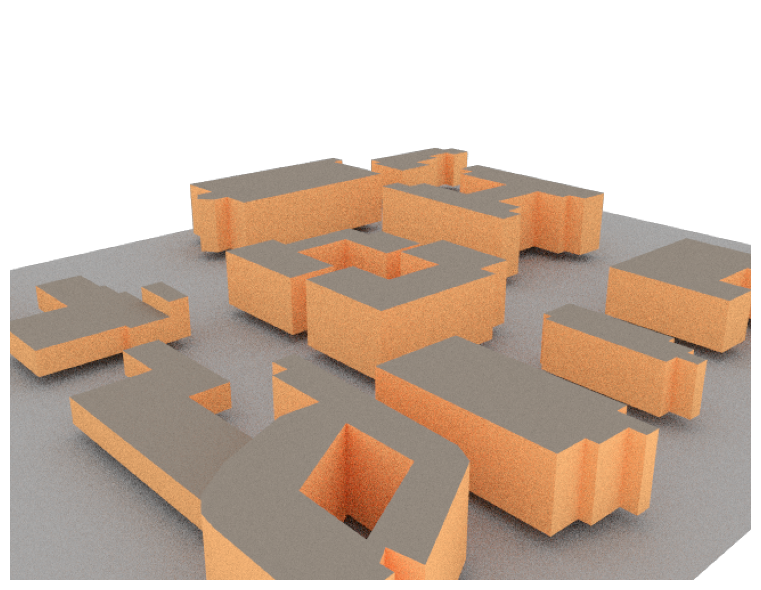

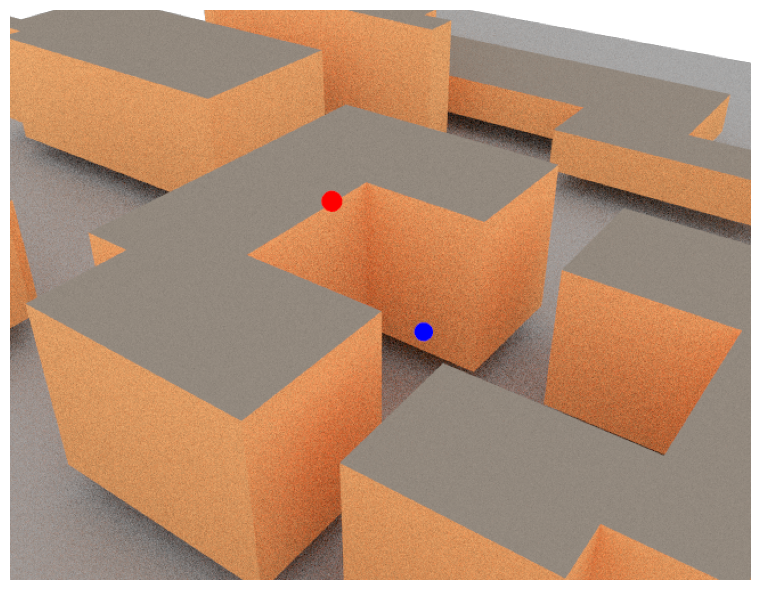

In [12]:
# environment and antenna
from sionna.rt import load_scene, Camera, PlanarArray, Transmitter, Receiver
from matplotlib import pyplot as plt

scene = load_scene("./NYCU_scene/NYCU.xml")
my_cam = Camera(position=[-250.1,250.1,150.1], look_at=[-15.001,30.1,28.1])
scene.render(camera=my_cam, resolution=[650, 500], num_samples=32)
plt.show()

scene.frequency = ENV["frequency"]
scene.tx_array = PlanarArray(**TX_ARRY)
scene.rx_array = PlanarArray(**RX_ARRY)

tx = Transmitter(name="tx", position=ENV["tx_position"], display_radius=1.5, color=(1, 0, 0))
rx = Receiver(name="rx", position=ENV["rx_position"], display_radius=1.5, color=(0, 0, 1))
scene.add(tx)
scene.add(rx)
tx.look_at(rx)
my_cam = Camera(position=[70, -90, 95], look_at=[5, 5, 18])
scene.render(camera=my_cam, resolution=[650, 500], num_samples=32)
plt.show()

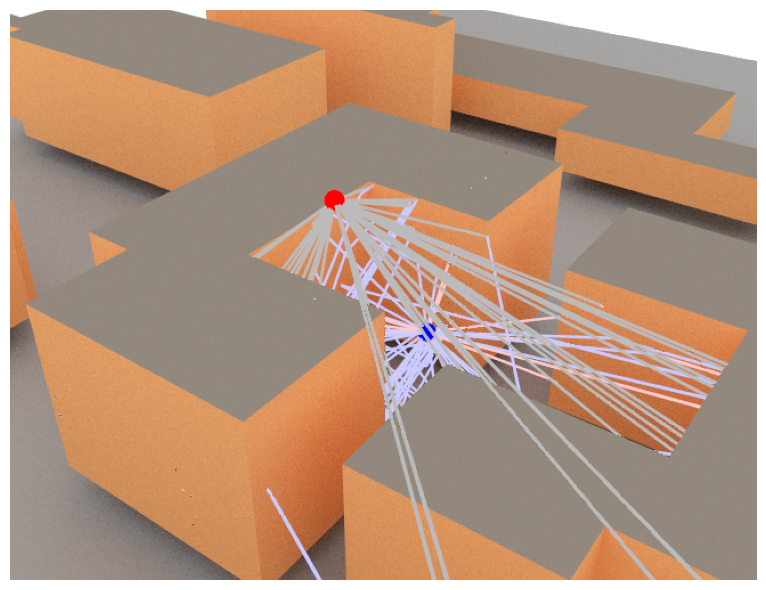

In [13]:
# channel
from sionna.rt import PathSolver
paths = PathSolver()(scene=scene, **PATHSOLVER_SETTING)

scene.render(camera=my_cam, paths=paths, clip_at=35)
plt.show()